In [1]:
import agama, numpy
from astropy import units as u 
from astropy import constants as cnst
import h5py 
from matplotlib import pyplot as plt 

In [2]:
def print_tree(group, indent=0):
    pad = "    " * indent
    for key, item in group.items():
        if isinstance(item, h5py.Group):          # public name; avoid h5py._hl.group.Group
            print(f"{pad}{key}/   ({len(item.attrs)} attrs)")
            print_tree(item, indent + 1)
        else:
            print(f"{pad}{key}   {item.shape} {item.dtype}")

In [3]:
# open the output file and analyze it 
myfile=h5py.File("ferrers_bar.h5",'r')
print_tree(myfile)

nbody_200/   (28 attrs)
    initial_conditions   (200, 6) float64
    mass   (200,) float64
    potential_energy_external   (20001, 200) float32
    potential_energy_internal   (20001, 200) float32
    time   (20001,) float64
    trajectories   (20001, 200, 6) float32
schwarzschild/   (30 attrs)
    gridr   (11,) float64
    ics   (2000, 6) float64
    inputs/   (0 attrs)
        bar_ini   () object
        ext_ini   () object
    mass_model   (191,) float64
    mass_true   (191,) float64
    matrix_data_density   (2000, 191) float32
    orbit_times   (2000,) float64
    potential/   (1 attrs)
        bar/   (5 attrs)
        halo/   (3 attrs)
        thick_disk/   (4 attrs)
        thin_disk/   (4 attrs)
    sigma   (191,) float64
    trajectories/   (0 attrs)
        data   (3263970, 6) float64
        offsets   (2001,) int64
        time   (3263970,) float64
    weights   (2000,) float64


In [14]:
group = "nbody_200"
mass = myfile[group]["mass"][:]
potential_energy_external = mass*myfile[group]["potential_energy_external"][:]
potential_energy_internal = 0.5*mass*myfile[group]["potential_energy_internal"][:]
kinetic_energy = (1/2)*mass*numpy.sum(myfile[group]["trajectories"][:,:,3:6]**2,axis=2)
timesteps = myfile[group]["time"][:]

In [15]:
E_total = potential_energy_external + potential_energy_internal + kinetic_energy
total_energy = numpy.sum(E_total,axis=1)
eDrift = numpy.abs((total_energy - total_energy[0]) / total_energy[0])

show the bar frame

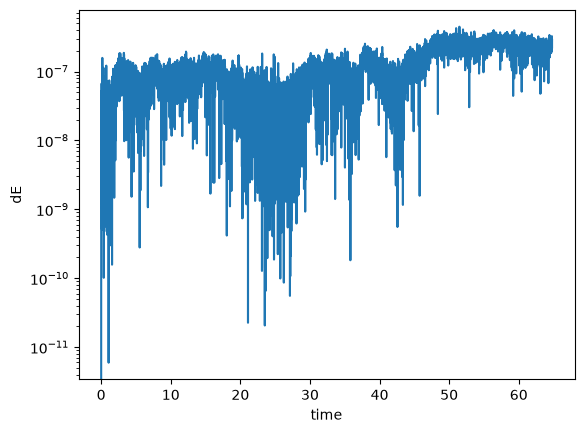

In [16]:
fig,axis=plt.subplots(1,1)
axis.plot(timesteps,eDrift)
axis.set(xlabel="time",ylabel="dE",yscale="log")
fig.savefig(f"test_total_energy_conservation_{group}.png",dpi=300)